In [1]:

%load_ext autoreload
%autoreload 2

### Section 1: Visualize `MaierStein_pts.csv`
which can be found in the external data directory.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from MaierSteinSolver.config import EXTERNAL_DATA_DIR

2026-11-15 12:00:01.234 | INFO     | MaierSteinSolver.config:<module>:11 - PROJ_ROOT path is: /Users/williamclark/Documents/UMD_REU_Code_cleanup/MaierStein-Solver-CookieCutter-parent/MaierSteinSolverRepo


In [4]:
pts = np.loadtxt(f'{EXTERNAL_DATA_DIR}/MaierStein_pts.csv', delimiter=',', dtype=float)

/var/folders/mh/gbj7v0tx7cn3t6x4ypc457mr0000gn/T/ipykernel_51501/818607714.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


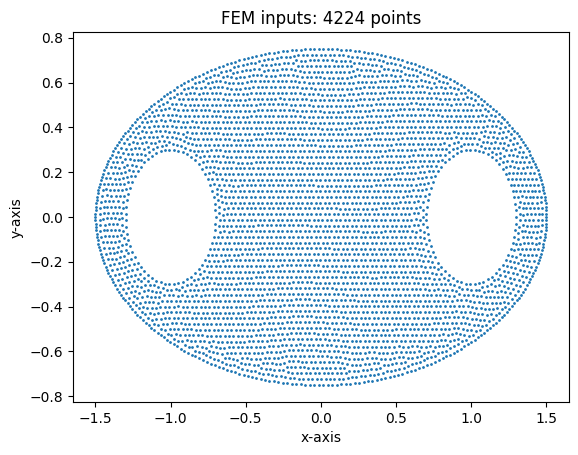

In [5]:
fig, ax = plt.subplots()
ax.scatter(pts[:,0], pts[:,1], s=1)
ax.set_xlabel("x-axis")
ax.set_ylabel("y-axis")
ax.set_title("FEM inputs: 4224 points")
fig.show()

### Section 2: Testing the make boundary data function

In [6]:
from MaierSteinSolver.dataset import make_bdy_csv

In [7]:
make_bdy_csv()

2026-11-15 12:00:08.112 | INFO     | MaierSteinSolver.dataset:make_bdy_csv:117 - Generating uniform samples from boundaries of A and B...
2026-11-15 12:00:08.159 | INFO     | MaierSteinSolver.dataset:make_bdy_csv:134 - Labeling with committor values...
2026-11-15 12:00:08.185 | SUCCESS  | MaierSteinSolver.dataset:make_bdy_csv:162 - Processing dataset complete.


### Section 3: Testing the make FEM prediction csv function:

In [37]:
from MaierSteinSolver.dataset import make_finite_elements_prediction_csv

In [38]:
make_finite_elements_prediction_csv()

2026-11-15 12:16:29.316 | INFO     | MaierSteinSolver.dataset:make_finite_elements_prediction_csv:101 - Processing dataset...
2026-11-15 12:16:29.380 | SUCCESS  | MaierSteinSolver.dataset:make_finite_elements_prediction_csv:113 - Processing dataset complete.


### Section 4: Test the make ellipse points csv function:

In [10]:
from MaierSteinSolver.dataset import make_ellipse_pts_csv

In [11]:
make_ellipse_pts_csv()

2026-11-15 12:00:21.410 | INFO     | MaierSteinSolver.dataset:make_ellipse_pts_csv:88 - Processing dataset...
2026-11-15 12:00:21.435 | SUCCESS  | MaierSteinSolver.dataset:make_ellipse_pts_csv:93 - Processing dataset complete.


### Section 5: Draw checkerboard sample from ellipse

In [12]:
from MaierSteinSolver.dataset import make_checkerboard_ellipse_train_dataset_csv

In [13]:
make_checkerboard_ellipse_train_dataset_csv()

2026-11-15 12:00:24.333 | INFO     | MaierSteinSolver.dataset:make_checkerboard_ellipse_train_dataset_csv:33 - Processing dataset...
2026-11-15 12:00:24.460 | SUCCESS  | MaierSteinSolver.dataset:make_checkerboard_ellipse_train_dataset_csv:84 - Processing dataset complete.


### Section 6: Plot Checkerboard sample from ellipse:

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from MaierSteinSolver.config import RAW_DATA_DIR


In [15]:
pts_df = pd.read_csv(f'{RAW_DATA_DIR}/CHECKERBOARD_ELLIPSE_2026-01-12T17:43.csv')
pts_df

,x,y
0,1.118306,0.467084
1,1.096824,0.467084
2,0.746979,0.467084
3,-0.007484,0.467084
4,-0.490502,0.467084
...,...,...
29194,0.246715,0.102701
29195,0.513157,0.102701
29196,-1.421508,0.102701
29197,-0.588943,0.102701


In [16]:
pts = pts_df.to_numpy()
pts.shape

(29199, 2)

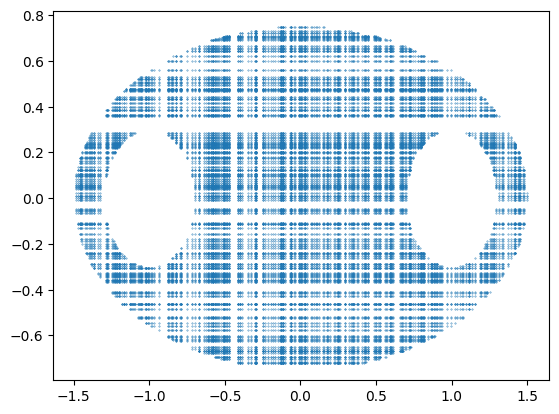

In [17]:
fig, ax = plt.subplots()
ax.scatter(pts[:,0], pts[:,1], s=0.1)
plt.show()

### Section 7: Plot checkerboard ellipse using plot.py:

In [18]:
from MaierSteinSolver.config import RAW_DATA_DIR
from MaierSteinSolver.plots import scatter_plot_csv

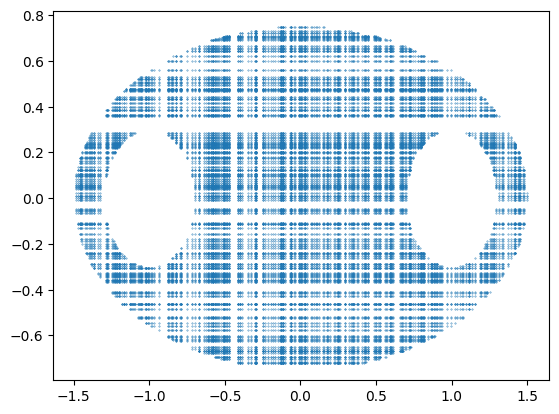

In [19]:
scatter_plot_csv(f'{RAW_DATA_DIR}/CHECKERBOARD_ELLIPSE_2026-01-12T17:43.csv')

### Section 8: Plot boundary data:

In [20]:
from MaierSteinSolver.config import RAW_DATA_DIR
from MaierSteinSolver.plots import scatter_plot_csv

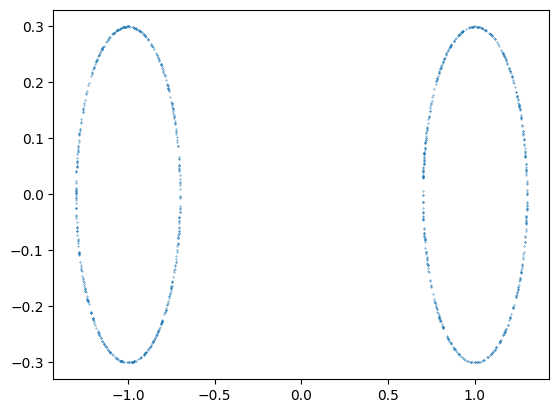

In [21]:
scatter_plot_csv(f'{RAW_DATA_DIR}/BOUNDARY_DATA_2026-01-12T12:05.csv')

### Section 9: Train a model

In [46]:
from MaierSteinSolver.modeling.train import main

In [ ]:
main("20,20")

2026-11-15 13:29:05.887 | INFO     | MaierSteinSolver.modeling.train:main:30 - Training some model...


100%|██████████| 10/10 [00:00<00:00, 3255.18it/s]

2026-11-15 13:29:05.891 | INFO     | MaierSteinSolver.modeling.train:main:33 - Something happened for iteration 5.
2026-11-15 13:29:05.895 | SUCCESS  | MaierSteinSolver.modeling.train:main:34 - Modeling training complete.
2026-11-15 13:29:05.939 | INFO     | MaierSteinSolver.modeling.pinn:train:167 - Epoch 1
-------------------------------
loss: 2.696014  [    0/29199]


loss: 0.283166  [ 6400/29199]
loss: 0.046433  [12800/29199]
loss: 0.023157  [19200/29199]
loss: 0.015045  [25600/29199]
2026-11-15 13:29:08.686 | INFO     | MaierSteinSolver.modeling.pinn:train:167 - Epoch 2
-------------------------------
loss: 0.012302  [    0/29199]
loss: 0.010941  [ 6400/29199]
loss: 0.006727  [12800/29199]
loss: 0.006739  [19200/29199]
loss: 0.005146  [25600/29199]
2026-11-15 13:29:11.410 | INFO     | MaierSteinSolver.modeling.pinn:train:167 - Epoch 3
-------------------------------
loss: 0.007379  [    0/29199]
loss: 0.007776  [ 6400/29199]
loss: 0.008604  [12800/29199]
loss: 0.006066  [19200/29199]
loss: 0.006603  [25600/29199]
2026-11-15 13:29:14.402 | INFO     | MaierSteinSolver.modeling.pinn:train:167 - Epoch 4
-------------------------------
loss: 0.006912  [    0/29199]
loss: 0.005821  [ 6400/29199]
loss: 0.005750  [12800/29199]
loss: 0.005280  [19200/29199]
loss: 0.005488  [25600/29199]
2026-11-15 13:29:17.514 | INFO     | MaierSteinSolver.modeling.pinn:tr

### Section 10: Make Predictions

In [48]:
from MaierSteinSolver.modeling.predict import main

In [49]:
main()

2026-11-15 13:30:19.086 | INFO     | MaierSteinSolver.modeling.predict:main:26 - Performing inference for model...


100%|██████████| 10/10 [00:00<00:00, 1200.50it/s]

2026-11-15 13:30:19.094 | INFO     | MaierSteinSolver.modeling.predict:main:29 - Something happened for iteration 5.
2026-11-15 13:30:19.106 | SUCCESS  | MaierSteinSolver.modeling.predict:main:30 - Inference complete.


### Section 11: Plot the committor: 

In [7]:
from MaierSteinSolver.plots import plot_q

2026-11-15 20:33:29.674 | INFO     | MaierSteinSolver.plots:plot_q:36 - Plotting the committor function.


(<Figure size 640x480 with 2 Axes>, <Axes: >)

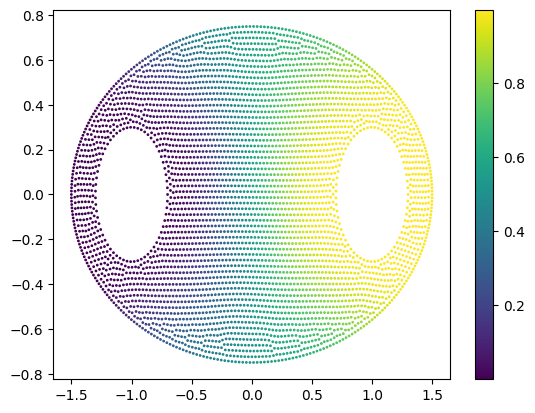

In [8]:
plot_q()

### Section 12: Plot the Committor found by the finite element method. 

In [9]:
from MaierSteinSolver.plots import plot_q
from MaierSteinSolver.config import PROCESSED_DATA_DIR

2026-11-15 20:33:41.582 | INFO     | MaierSteinSolver.plots:plot_q:36 - Plotting the committor function.


(<Figure size 640x480 with 2 Axes>, <Axes: >)

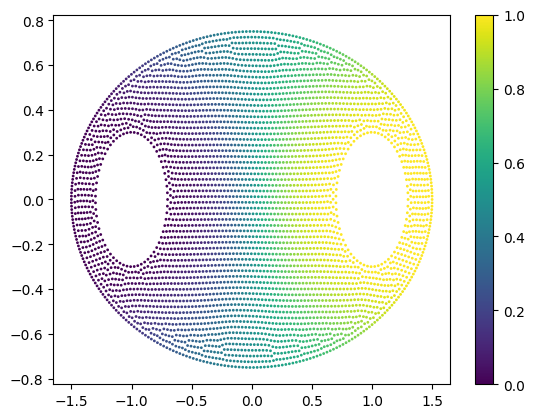

In [10]:
plot_q(f'{PROCESSED_DATA_DIR}/FEM_Commitor.csv')

### Section 13: Compare FEM Committor and Neural Network Solver Committor

In [11]:
from MaierSteinSolver.plots import compare_fem_absolute

(<Figure size 640x480 with 2 Axes>, <Axes: >)

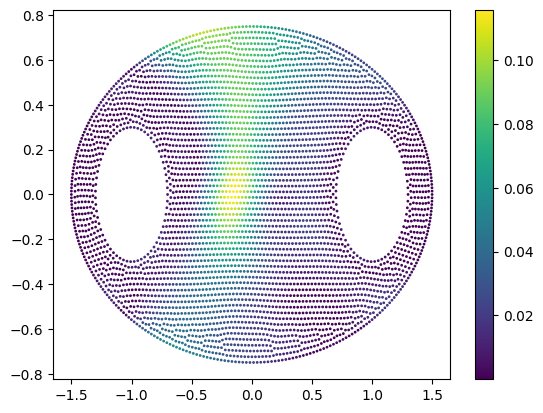

In [12]:
compare_fem_absolute()